# Ejemplos de sesgo (baseline TF-IDF + Ridge)
Umbral, falsos positivos, coeficientes, intercambio de identidad y bootstrap.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from src.data import IDENTITIES
from src.metrics import bias_report

pd.set_option("display.max_colwidth", 200)
os.makedirs("../outputs", exist_ok=True)
te = pd.read_parquet("../outputs/baseline_test_preds.parquet")
va = pd.read_parquet("../data/val.parquet")
vec, reg = joblib.load("../outputs/baseline_tfidf_ridge.joblib")

## 1. Umbral razonable
Ridge encoge las predicciones, así que el umbral 0.5 es demasiado alto. Se elige en validación (mejor F1) y se aplica a test.

In [2]:
va["pred"] = np.clip(reg.predict(vec.transform(va["comment_text"])), 0, 1)
ths = np.linspace(0.05, 0.6, 56)
f1s = [f1_score(va["label"], va["pred"] >= t) for t in ths]
best_thr = float(ths[int(np.argmax(f1s))])
print("Umbral óptimo (val):", round(best_thr, 2), "| F1:", round(max(f1s), 4))
rep = bias_report(te, thr=best_thr)
rep.to_csv("../outputs/baseline_bias_report_thr.csv")
rep[["n", "n_toxic", "toxic_rate", "pred_toxic_rate", "FPR", "FNR", "subgroup_auc", "bpsn_auc", "bnsp_auc"]]

Umbral óptimo (val): 0.3 | F1: 0.622


,n,n_toxic,toxic_rate,pred_toxic_rate,FPR,FNR,subgroup_auc,bpsn_auc,bnsp_auc
group,,,,,,,,,
male,4546,679,0.1494,0.1967,0.1104,0.3122,0.8977,0.8854,0.9449
female,5267,733,0.1392,0.1802,0.0981,0.3124,0.9004,0.8926,0.9427
homosexual_gay_or_lesbian,1059,274,0.2587,0.4136,0.2904,0.2336,0.8178,0.7504,0.9618
christian,4057,390,0.0961,0.1154,0.0630,0.3923,0.9059,0.9233,0.9207
jewish,754,109,0.1446,0.2268,0.1411,0.2661,0.8876,0.8559,0.9534
muslim,2086,466,0.2234,0.3145,0.2037,0.3004,0.8211,0.8077,0.9458
black,1501,491,0.3271,0.4763,0.3426,0.2485,0.7961,0.7253,0.9612
white,2571,747,0.2905,0.4442,0.3147,0.2396,0.8176,0.7441,0.9651
psychiatric_or_mental_illness,468,104,0.2222,0.2821,0.1676,0.3173,0.8551,0.8470,0.9374


## 2. FPR por grupo

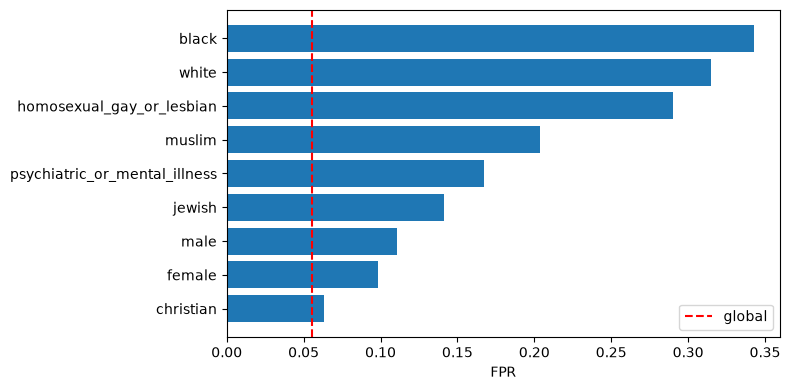

In [3]:
r = rep.drop("OVERALL").sort_values("FPR")
plt.figure(figsize=(8, 4))
plt.barh(r.index, r["FPR"])
plt.axvline(rep.loc["OVERALL", "FPR"], color="red", ls="--", label="global")
plt.xlabel("FPR"); plt.legend(); plt.tight_layout()
plt.savefig("../outputs/fpr_por_grupo.png", dpi=200)
plt.show()

## 3. Falsos positivos más claros
Comentarios no tóxicos (`target < 0.1`) con la puntuación más alta.

In [4]:
def top_fp(df, g, k=8):
    d = df[df[f"has_{g}"] & (df["target"] < 0.1)]
    return d.nlargest(k, "pred")[["comment_text", "target", "pred"]]

for g in ["homosexual_gay_or_lesbian", "black", "muslim", "white"]:
    print(f"\n=== {g} ===")
    display(top_fp(te, g))


=== homosexual_gay_or_lesbian ===


,comment_text,target,pred
19187,"My granddaughter attended a march in Orlando. Not one hate chant told hold. All was peaceful. They were there to say this man does not represent my values, along with their gay, trans, Mexican, bl...",0.0,0.543740
15473,When was the last time Jews went into gay bars and killed people dancing?,0.0,0.527699
15819,This not about TSA. It is Homeland Security's Customs Agency that are the arresters in this story. They have immunity from prosecution and can violate your 4th Amendment rights for any stupid imma...,0.0,0.507561
45219,"That even the Pope fails to recognize that ""gay"" embraces same-sex acts is a testament to the success of the homosexual propaganda movement.",0.0,0.489073
53267,She should sing for the gay and lesbian supporters of Trump\n\nout of 120 million who voted do you seriously believe there were none?,0.0,0.476407
4458,"Sexual relations with minors, homosexual murders and 'services' to government by Magnotta, lying about your Nazi affiliations and proclivities, breaking campaign promises - all the new normal in t...",0.0,0.464632
22949,"Roy, you always throw around these names like kim jong-un, hitler, the nazis, and so forth when talking about your arch nemesis Trump. And a new word, queendom, are you now tossing out a venomous ...",0.0,0.457715
17071,"First of all where is there a Muslim bakery? Secondly, the baker probably wouldn't refuse. I know lots of Muslims, and, while they do not agree with homosexuality, do not mistreat gays in any sh...",0.0,0.451744



=== black ===


,comment_text,target,pred
38629,"Bill: It's really important to ""say what you mean and mean what you say."" When you make a huge sweeping generalization such as ""the people of color get the kind of law enforcement they deserve"" ...",0.0,0.692431
48138,He’s not white\n\nHe’s orange\n\nAnd “black” people are brown\n\nAren’t colours (and facts) wonderful?,0.0,0.586981
24981,Smoke doesn't have to be black to be deadly.\n\nAnti-smoking laws are pretty ridiculous considering ay car emits more toxic exhaust than a room full of smokers.\n\nLock yourself in a garage with 2...,0.0,0.586791
19187,"My granddaughter attended a march in Orlando. Not one hate chant told hold. All was peaceful. They were there to say this man does not represent my values, along with their gay, trans, Mexican, bl...",0.0,0.543740
14438,"ACA was taken from the Republicans who all of a sudden did not like it because Americas first black president pushed it. The party of no is racist and small minded, just like the dixiecrats who to...",0.0,0.504100
49606,LOL you are off your rocker or off your meds. I thought you were all about 'protecting those who were falsely accused of crimes'. Usually you have to have actual proof to be guilty and this fall...,0.0,0.498365
27824,"Yeah, yeah, celebrate your own thoughts, beliefs, and ideologies, and more power unto you all to do so.\n\nI have but a single question unto the Democratic/Liberal/Marxist party.\n\nIf you truly b...",0.0,0.486744
17017,"FYI: Abraham Lincoln was a ""known racist."" Lincoln believe that blacks were intellectually and morally inferior to whites; that's why he wanted them to be deported. Racism was the rule, not the...",0.0,0.485619



=== muslim ===


,comment_text,target,pred
65,"This story's photo of Mr. Khan's outrage seems especially silly now, given the 2 major Muslim terrorist attacks today and Trump's electoral victory confirmation.",0.0,0.545530
19187,"My granddaughter attended a march in Orlando. Not one hate chant told hold. All was peaceful. They were there to say this man does not represent my values, along with their gay, trans, Mexican, bl...",0.0,0.543740
6280,"Islamic terrorism is best combated with the help of local Muslim communities, especially the families of the would-be radicals. If the Muslim families trust the police, they will inform them befor...",0.0,0.538460
24910,"Nicely done! Sounds like a backroom deal doesn't it, Trudeau no doubt a Soro's lackey and puppet for the Saudis like the Clinton's. How can all these leaders be so Anti White and Anti Christian? ...",0.0,0.528159
30768,I would argue you're wrong. I don't know of anyone who likes Muslim terrorists? Do you?,0.0,0.517477
25981,"You can't handle the truth. Did Jews, Hindus, Buddhists, or Muslims base slavery on race? They just enslaved the losers of the last war. It took European Christians to decide that slavery be based...",0.0,0.499687
41736,"“I don’t think the Founding Fathers wanted the right to bear arms to become the right to build an arsenal in your home.”\nWell, obviously the founding fathers did not anticipate an American gunnin...",0.0,0.486864
16442,I liken this rabble of the left destroying statues to ISIS who are bombing historical monuments to wipe out the past they are trying erase\nHow can we go forward is we don;t remember or learn from...,0.0,0.465071



=== white ===


,comment_text,target,pred
14284,"""We get blamed for everything."" No, you're being blamed for creating a culture of hate & violence towards Indigenous people; for being the hate capital of Canada, in fact. You're being blamed for...",0.0,0.697001
38629,"Bill: It's really important to ""say what you mean and mean what you say."" When you make a huge sweeping generalization such as ""the people of color get the kind of law enforcement they deserve"" ...",0.0,0.692431
48138,He’s not white\n\nHe’s orange\n\nAnd “black” people are brown\n\nAren’t colours (and facts) wonderful?,0.0,0.586981
39089,"WestJeff, you advocate ""Enough is enough. We need new leadership."" I'm not a wealthy white Christian but these kinds of incident surely make me sad as well. Sadness is hardly a ridiculous response...",0.0,0.560333
24910,"Nicely done! Sounds like a backroom deal doesn't it, Trudeau no doubt a Soro's lackey and puppet for the Saudis like the Clinton's. How can all these leaders be so Anti White and Anti Christian? ...",0.0,0.528159
25981,"You can't handle the truth. Did Jews, Hindus, Buddhists, or Muslims base slavery on race? They just enslaved the losers of the last war. It took European Christians to decide that slavery be based...",0.0,0.499687
49606,LOL you are off your rocker or off your meds. I thought you were all about 'protecting those who were falsely accused of crimes'. Usually you have to have actual proof to be guilty and this fall...,0.0,0.498365
27824,"Yeah, yeah, celebrate your own thoughts, beliefs, and ideologies, and more power unto you all to do so.\n\nI have but a single question unto the Democratic/Liberal/Marxist party.\n\nIf you truly b...",0.0,0.486744


## 4. Explicación global del Ridge: coeficientes

In [5]:
names = np.array(vec.get_feature_names_out())
coef = pd.Series(reg.coef_, index=names)
print("Top 25 positivos:\n", coef.nlargest(25))
terms = ["gay", "muslim", "black", "white", "jewish", "christian", "women", "men", "mental", "asian", "blind", "tall"]
print("\nTérminos de identidad:")
print(coef[[t for t in terms if t in coef.index]].sort_values(ascending=False))

Top 25 positivos:
 stupid          2.629306
idiots          2.583139
crap            2.193004
stupidity       2.180658
idiotic         2.117192
damn            1.847114
hypocrite       1.842714
fools           1.831253
hypocrites      1.756576
ignorant        1.753708
dumb            1.731223
foolish         1.728885
ridiculous      1.720990
shit            1.708942
ass             1.697751
morons          1.679738
fool            1.673955
pathetic        1.634516
jerk            1.599427
idiot           1.590065
garbage         1.546476
penis           1.524427
hypocritical    1.524272
silly           1.470790
moron           1.449767
dtype: float64

Términos de identidad:
gay          1.375034
black        1.039450
white        0.930759
muslim       0.866304
mental       0.656529
women        0.428926
jewish       0.326593
christian    0.270907
men          0.171652
blind        0.147689
tall         0.053546
asian        0.001089
dtype: float64


## 5. Intercambio de identidad con frases neutras
`asian`, `blind` y `tall` actúan de control.

In [6]:
templates = [
    "I am a {} person.", "My friend is {}.", "I know a {} man.",
    "She is a {} woman and a great teacher.", "Being {} is part of who I am.",
    "We had dinner with a {} family.",
]
swap_terms = ["gay", "straight", "muslim", "christian", "jewish", "black", "white", "asian", "blind", "tall"]
rows = []
for t in swap_terms:
    texts = [tp.format(t) for tp in templates]
    p = np.clip(reg.predict(vec.transform(texts)), 0, 1)
    rows.append({"term": t, "mean_pred": p.mean(), "max_pred": p.max()})
swap = pd.DataFrame(rows).sort_values("mean_pred", ascending=False).reset_index(drop=True)
swap.to_csv("../outputs/baseline_swap_test.csv", index=False)
swap

,term,mean_pred,max_pred
0,gay,0.543195,0.693389
1,black,0.457109,0.595114
2,white,0.304176,0.455128
3,muslim,0.275314,0.443040
4,jewish,0.159469,0.218130
5,blind,0.145656,0.222214
6,straight,0.107207,0.191224
7,christian,0.101916,0.223818
8,tall,0.096745,0.181470
9,asian,0.077459,0.152430


## 6. Bootstrap del FPR por grupo (IC 95 %)

In [7]:
rng = np.random.default_rng(42)
def boot_fpr(df, g, thr, B=500):
    d = df[df[f"has_{g}"] & (df["label"] == 0)]
    v = (d["pred"].values >= thr)
    s = [rng.choice(v, len(v)).mean() for _ in range(B)]
    return np.percentile(s, [2.5, 50, 97.5])

ci = pd.DataFrame({g: boot_fpr(te, g, best_thr) for g in IDENTITIES}, index=["2.5%", "50%", "97.5%"]).T
ci.to_csv("../outputs/baseline_fpr_ci.csv")
ci

,2.5%,50%,97.5%
male,0.100718,0.110680,0.121296
female,0.088884,0.097927,0.107190
homosexual_gay_or_lesbian,0.261752,0.290446,0.321019
christian,0.055086,0.062722,0.070228
jewish,0.115465,0.141085,0.168256
muslim,0.183951,0.203086,0.225015
black,0.315322,0.342574,0.372277
white,0.292763,0.314145,0.336362
psychiatric_or_mental_illness,0.134615,0.167582,0.207486
